# 01 - Análise Exploratória

Objetivo: perfilar o dataset de e-commerce, medir o desbalanceamento da classe `is_fraud` e identificar sinais comportamentais antes da limpeza e da seleção de features.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT))

from src.data.cleaning import load_raw, report_missing

RAW_PATH = ROOT / "data" / "raw" / "transactions.csv"
FIGURES_DIR = ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 4)

Matplotlib is building the font cache; this may take a moment.


## Carregamento e visão geral

In [2]:
df = load_raw(RAW_PATH)
print(f"Shape: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
df.head()

Shape: 299,695 linhas × 17 colunas


,transaction_id,user_id,account_age_days,total_transactions_user,avg_amount_user,amount,country,bin_country,channel,merchant_category,promo_used,avs_match,cvv_result,three_ds_flag,transaction_time,shipping_distance_km,is_fraud
0,1,1,141,47,147.93,84.75,FR,FR,web,travel,0,1,1,1,2024-01-06T04:09:39Z,370.95,0
1,2,1,141,47,147.93,107.90,FR,FR,web,travel,0,0,0,0,2024-01-09T20:13:47Z,149.62,0
2,3,1,141,47,147.93,92.36,FR,FR,app,travel,1,1,1,1,2024-01-12T06:20:11Z,164.08,0
3,4,1,141,47,147.93,112.47,FR,FR,web,fashion,0,1,1,1,2024-01-15T17:00:04Z,397.40,0
4,5,1,141,47,147.93,132.91,FR,US,web,electronics,0,1,1,1,2024-01-17T01:27:31Z,935.28,0


In [3]:
df.info()
df.describe(include="number").T

<class 'pandas.DataFrame'>
RangeIndex: 299695 entries, 0 to 299694
Data columns (total 17 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   transaction_id           299695 non-null  int64  
 1   user_id                  299695 non-null  int64  
 2   account_age_days         299695 non-null  int64  
 3   total_transactions_user  299695 non-null  int64  
 4   avg_amount_user          299695 non-null  float64
 5   amount                   299695 non-null  float64
 6   country                  299695 non-null  str    
 7   bin_country              299695 non-null  str    
 8   channel                  299695 non-null  str    
 9   merchant_category        299695 non-null  str    
 10  promo_used               299695 non-null  int64  
 11  avs_match                299695 non-null  int64  
 12  cvv_result               299695 non-null  int64  
 13  three_ds_flag            299695 non-null  int64  
 14  transaction_tim

,count,mean,std,min,25%,50%,75%,max
transaction_id,299695.0,149848.000000,86514.638800,1.00,74924.50,149848.00,224771.50,299695.00
user_id,299695.0,3002.559432,1732.309663,1.00,1501.00,3007.00,4504.00,6000.00
account_age_days,299695.0,973.397871,525.241409,1.00,516.00,975.00,1425.00,1890.00
total_transactions_user,299695.0,50.673321,5.976391,40.00,46.00,51.00,56.00,60.00
avg_amount_user,299695.0,148.142973,200.364624,3.52,46.19,90.13,173.45,4565.29
amount,299695.0,177.165279,306.926507,1.00,42.10,89.99,191.11,16994.74
promo_used,299695.0,0.153640,0.360603,0.00,0.00,0.00,0.00,1.00
avs_match,299695.0,0.837999,0.368453,0.00,1.00,1.00,1.00,1.00
cvv_result,299695.0,0.872110,0.333968,0.00,1.00,1.00,1.00,1.00
three_ds_flag,299695.0,0.784588,0.411109,0.00,1.00,1.00,1.00,1.00


## Qualidade básica

In [4]:
missing = report_missing(df)
print("Valores ausentes:")
display(missing if not missing.empty else "Nenhum valor ausente.")
print(f"Linhas duplicadas: {df.duplicated().sum():,}")
print(f"transaction_id únicos: {df['transaction_id'].nunique():,} / {len(df):,}")
print(f"Usuários únicos: {df['user_id'].nunique():,}")

Valores ausentes:


'Nenhum valor ausente.'

Linhas duplicadas: 0
transaction_id únicos: 299,695 / 299,695
Usuários únicos: 6,000


## Classe alvo (`is_fraud`)

,count,rate
is_fraud,,
legítima,293083,0.977938
fraude,6612,0.022062


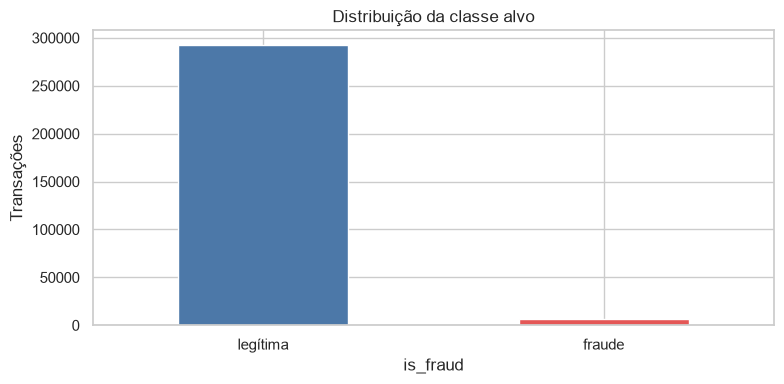

In [5]:
target_counts = df["is_fraud"].value_counts().rename({0: "legítima", 1: "fraude"})
target_rate = df["is_fraud"].value_counts(normalize=True).rename({0: "legítima", 1: "fraude"})
summary = pd.DataFrame({"count": target_counts, "rate": target_rate})
display(summary)

ax = summary["count"].plot(kind="bar", color=["#4C78A8", "#E45756"], rot=0)
ax.set_title("Distribuição da classe alvo")
ax.set_ylabel("Transações")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_target_distribution.png", dpi=120)
plt.show()

## Sinais categóricos e de segurança

,level,fraud_rate,feature
11,0,0.106058,cvv_result
9,0,0.096661,avs_match
13,0,0.067521,three_ds_flag
8,1,0.045282,promo_used
1,web,0.035644,channel
6,travel,0.023163,merchant_category
2,electronics,0.022534,merchant_category
3,fashion,0.022408,merchant_category
4,gaming,0.021641,merchant_category
5,grocery,0.020563,merchant_category


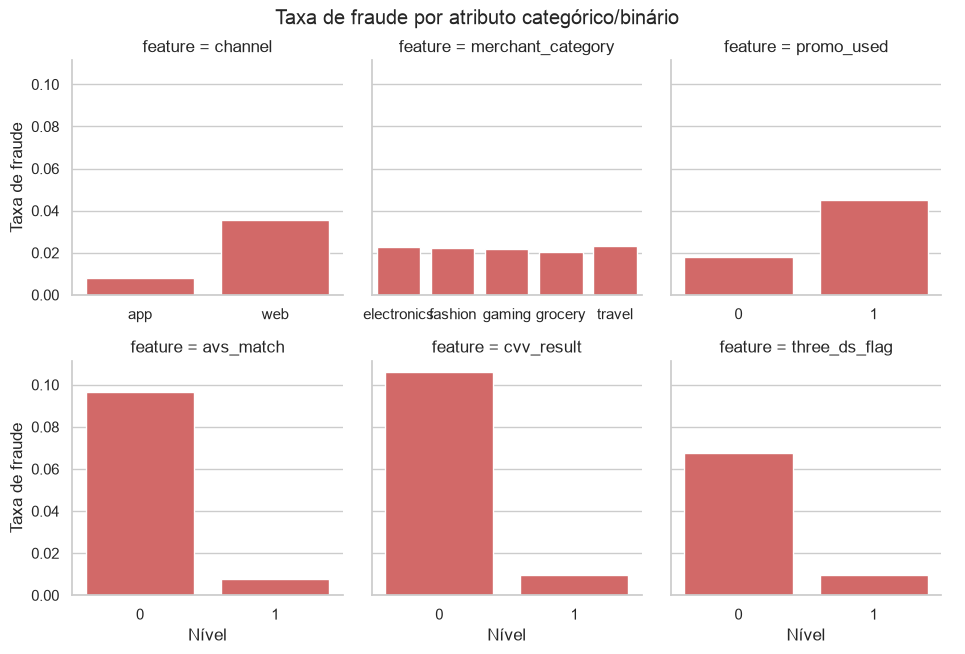

In [6]:
cat_cols = ["channel", "merchant_category", "promo_used", "avs_match", "cvv_result", "three_ds_flag"]
rates = []
for col in cat_cols:
    tmp = (
        df.groupby(col)["is_fraud"]
        .mean()
        .rename("fraud_rate")
        .reset_index()
        .assign(feature=col)
        .rename(columns={col: "level"})
    )
    rates.append(tmp)
rates_df = pd.concat(rates, ignore_index=True)
rates_df["level"] = rates_df["level"].astype(str)
display(rates_df.sort_values("fraud_rate", ascending=False))

g = sns.catplot(
    data=rates_df,
    x="level",
    y="fraud_rate",
    col="feature",
    kind="bar",
    col_wrap=3,
    sharex=False,
    color="#E45756",
    height=3.2,
)
g.set_axis_labels("Nível", "Taxa de fraude")
g.figure.suptitle("Taxa de fraude por atributo categórico/binário", y=1.02)
g.figure.savefig(FIGURES_DIR / "01_fraud_rate_by_category.png", dpi=120, bbox_inches="tight")
plt.show()

## País do usuário vs país do BIN do cartão

In [7]:
mismatch = (df["country"] != df["bin_country"]).astype(int)
print("Taxa de mismatch country/bin_country:", f"{mismatch.mean():.2%}")
print("Taxa de fraude com match:", f"{df.loc[mismatch == 0, 'is_fraud'].mean():.2%}")
print("Taxa de fraude com mismatch:", f"{df.loc[mismatch == 1, 'is_fraud'].mean():.2%}")

Taxa de mismatch country/bin_country: 7.92%
Taxa de fraude com match: 1.43%
Taxa de fraude com mismatch: 11.28%


## Variáveis numéricas vs fraude

/var/folders/52/l1fjlcs504q6t4mp8ft1xl7r0000gn/T/ipykernel_31554/3045314673.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/52/l1fjlcs504q6t4mp8ft1xl7r0000gn/T/ipykernel_31554/3045314673.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


/var/folders/52/l1fjlcs504q6t4mp8ft1xl7r0000gn/T/ipykernel_31554/3045314673.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/52/l1fjlcs504q6t4mp8ft1xl7r0000gn/T/ipykernel_31554/3045314673.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


/var/folders/52/l1fjlcs504q6t4mp8ft1xl7r0000gn/T/ipykernel_31554/3045314673.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


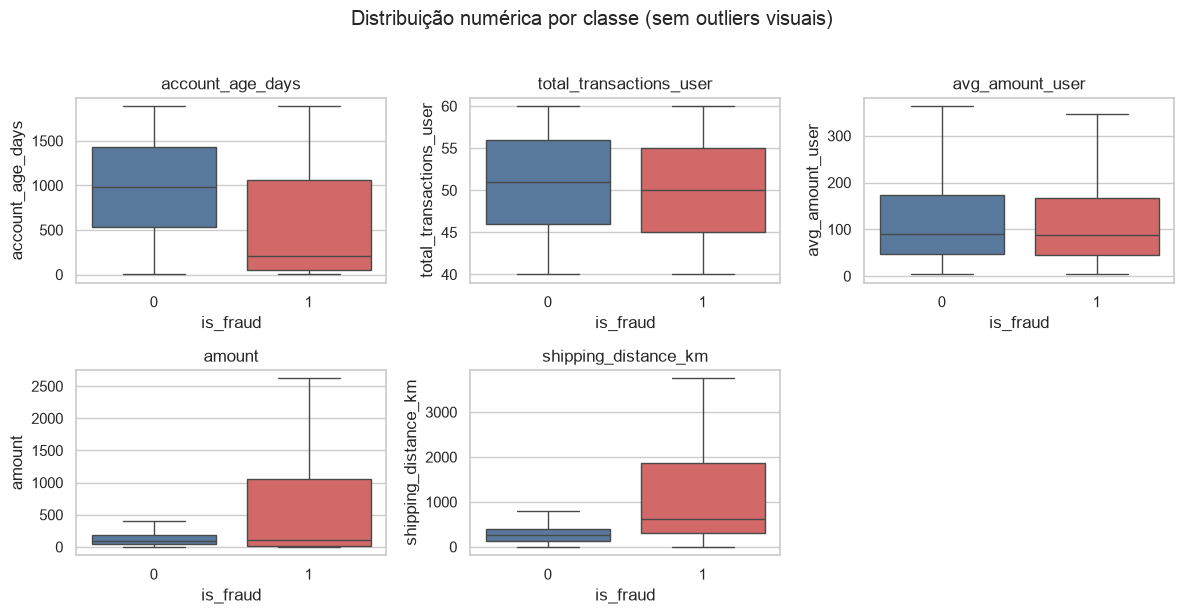

In [8]:
num_cols = [
    "account_age_days",
    "total_transactions_user",
    "avg_amount_user",
    "amount",
    "shipping_distance_km",
]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
axes = axes.ravel()
for ax, col in zip(axes, num_cols):
    sns.boxplot(
        data=df,
        x="is_fraud",
        y=col,
        ax=ax,
        showfliers=False,
        palette=["#4C78A8", "#E45756"],
    )
    ax.set_title(col)
    ax.set_xlabel("is_fraud")
axes[-1].axis("off")
fig.suptitle("Distribuição numérica por classe (sem outliers visuais)", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_numeric_by_target.png", dpi=120, bbox_inches="tight")
plt.show()

## Correlação numérica com o alvo

,corr_with_is_fraud
shipping_distance_km,0.270004
avs_match,-0.223299
cvv_result,-0.218982
amount,0.202499
three_ds_flag,-0.162160
account_age_days,-0.120340
promo_used,0.067351
total_transactions_user,-0.017093
avg_amount_user,-0.001236


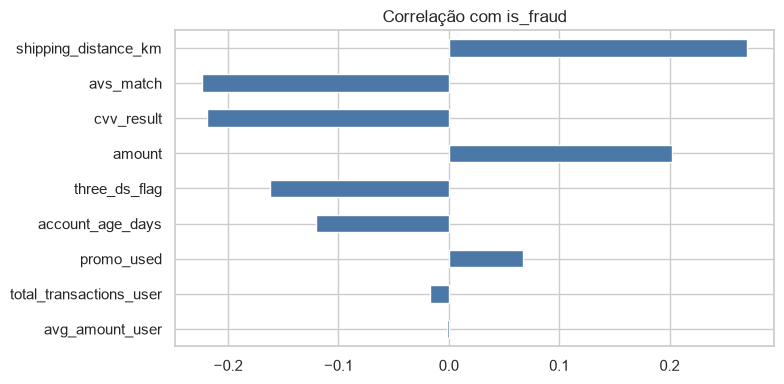

In [9]:
corr = (
    df.select_dtypes("number")
    .corr(numeric_only=True)["is_fraud"]
    .drop(labels=["is_fraud", "transaction_id", "user_id"], errors="ignore")
    .sort_values(key=abs, ascending=False)
)
display(corr.to_frame("corr_with_is_fraud"))

ax = corr.plot(kind="barh", color="#4C78A8")
ax.set_title("Correlação com is_fraud")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_correlation_target.png", dpi=120)
plt.show()

## Achados da EDA

- Base com ~300k transações, ~6k usuários, **sem nulos e sem duplicatas**.
- Classe fortemente desbalanceada: **~2,2% de fraude**.
- Sinais fortes preliminares: falha de `avs_match` / `cvv_result`, ausência de `three_ds_flag`, uso de `promo_used`, canal `web`, mismatch `country`≠`bin_country`, `amount` e `shipping_distance_km` elevados.
- Extremos de valor/distância não parecem erro de coleta - acompanham fraude e devem ser preservados na limpeza.